Data shape: (300, 2)
    x_km   y_km
0  1.893  8.006
1  2.370  7.114
2  2.809  1.858
3  1.028  8.129
4  8.939  2.457


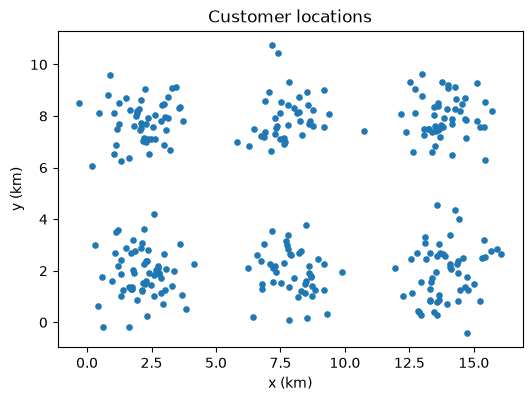

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("ic272_lab9_customers.csv")
X = df[["x_km", "y_km"]].to_numpy(dtype=float)

print("Data shape:", X.shape)
print(df.head())

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X[:, 0], X[:, 1], s=14)
ax.set_xlabel("x (km)")
ax.set_ylabel("y (km)")
ax.set_aspect("equal")
ax.set_title("Customer locations")
plt.show()

In [14]:
def random_init(X, K, seed):
    """Choose K distinct data points as the initial centroids."""
    idx = np.random.default_rng(seed).choice(len(X), K, replace=False)
    return X[idx].copy()


def pairwise_distances(A, B):
   
    differences = A[:, np.newaxis, :] - B[np.newaxis, :, :]
    # print("sag")
    # print(differences)
    return np.sqrt(np.sum(differences ** 2, axis=2))

In [4]:
def assign_clusters(X, centroids):
    
    distances = pairwise_distances(X, centroids)
    return np.argmin(distances, axis=1)


def update_centroids(X, labels, centroids):
    
    new_centroids = centroids.copy()

    for k in range(len(centroids)):
        points_in_cluster = X[labels == k]

        if len(points_in_cluster) > 0:
            new_centroids[k] = np.mean(points_in_cluster, axis=0)

    return new_centroids


def distortion(X, labels, centroids):
    
    differences = X - centroids[labels]
    return np.sum(differences ** 2)


def kmeans(X, init_centroids, max_iter=100):
   
    centroids = init_centroids.copy()

    for iteration in range(1, max_iter + 1):
        labels = assign_clusters(X, centroids)
        new_centroids = update_centroids(X, labels, centroids)

        if np.allclose(new_centroids, centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    labels = assign_clusters(X, centroids)
    J = distortion(X, labels, centroids)

    return centroids, labels, J, iteration

In [10]:

X_check = np.array([
    [0.0, 0.0], [0.2, 0.1], [0.1, 0.3],
    [5.0, 5.0], [5.2, 5.1], [4.9, 5.2],
    [10.0, 0.0], [10.2, 0.1], [9.9, 0.2]
])

initial_check = X_check[[0, 3, 6]].copy()
centres_check, labels_check, J_check, iters_check = kmeans(
    X_check, initial_check
)

print("Final centroids:\n", centres_check)
print("Distortion:", J_check)
print("Iterations:", iters_check)

sag
[[[  0.    0. ]
  [ -5.   -5. ]
  [-10.    0. ]]

 [[  0.2   0.1]
  [ -4.8  -4.9]
  [ -9.8   0.1]]

 [[  0.1   0.3]
  [ -4.9  -4.7]
  [ -9.9   0.3]]

 [[  5.    5. ]
  [  0.    0. ]
  [ -5.    5. ]]

 [[  5.2   5.1]
  [  0.2   0.1]
  [ -4.8   5.1]]

 [[  4.9   5.2]
  [ -0.1   0.2]
  [ -5.1   5.2]]

 [[ 10.    0. ]
  [  5.   -5. ]
  [  0.    0. ]]

 [[ 10.2   0.1]
  [  5.2  -4.9]
  [  0.2   0.1]]

 [[  9.9   0.2]
  [  4.9  -4.8]
  [ -0.1   0.2]]]
sag
[[[-1.00000000e-01 -1.33333333e-01]
  [-5.03333333e+00 -5.10000000e+00]
  [-1.00333333e+01 -1.00000000e-01]]

 [[ 1.00000000e-01 -3.33333333e-02]
  [-4.83333333e+00 -5.00000000e+00]
  [-9.83333333e+00 -1.38777878e-17]]

 [[-1.38777878e-17  1.66666667e-01]
  [-4.93333333e+00 -4.80000000e+00]
  [-9.93333333e+00  2.00000000e-01]]

 [[ 4.90000000e+00  4.86666667e+00]
  [-3.33333333e-02 -1.00000000e-01]
  [-5.03333333e+00  4.90000000e+00]]

 [[ 5.10000000e+00  4.96666667e+00]
  [ 1.66666667e-01 -8.88178420e-16]
  [-4.83333333e+00  5.00000000

In [15]:

K = 6
runs = []

for seed in range(10):
    initial_centroids = random_init(X, K, seed)
    centres, labels, J, iterations = kmeans(X, initial_centroids)

    runs.append({
        "seed": seed,
        "centroids": centres,
        "labels": labels,
        "J": J,
        "iterations": iterations
    })

    print(f"Seed {seed}: J = {J:.3f}, iterations = {iterations}")

best_run = min(runs, key=lambda result: result["J"])
worst_run = max(runs, key=lambda result: result["J"])

print("\nBest seed:", best_run["seed"], "Best J:", best_run["J"])
print("Worst seed:", worst_run["seed"], "Worst J:", worst_run["J"])

Seed 0: J = 476.247, iterations = 12
Seed 1: J = 476.247, iterations = 5
Seed 2: J = 476.247, iterations = 4
Seed 3: J = 1404.594, iterations = 4
Seed 4: J = 1404.940, iterations = 6
Seed 5: J = 476.247, iterations = 6
Seed 6: J = 476.247, iterations = 5
Seed 7: J = 1384.116, iterations = 8
Seed 8: J = 476.247, iterations = 5
Seed 9: J = 476.247, iterations = 11

Best seed: 0 Best J: 476.24680913904047
Worst seed: 4 Worst J: 1404.939583446746


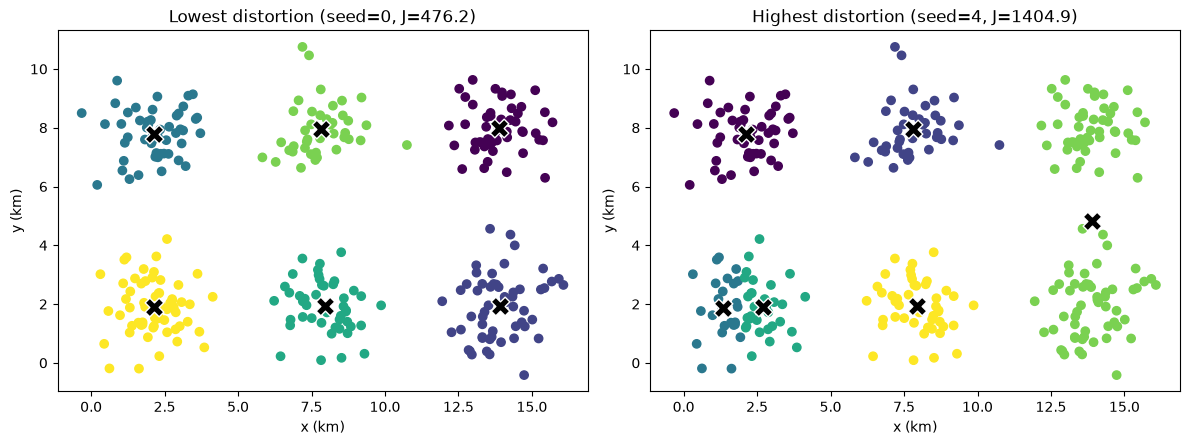

In [18]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, result, title in [
    (axes[0], best_run, "Lowest distortion"),
    (axes[1], worst_run, "Highest distortion")
]:
    ax.scatter(
        X[:, 0], X[:, 1],
        c=result["labels"]
    )
    ax.scatter(
        result["centroids"][:, 0],
        result["centroids"][:, 1],
        marker="X", s=180, c="black", edgecolors="white"
    )
    ax.set_title(f"{title} (seed={result['seed']}, J={result['J']:.1f})")
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [20]:
def best_of_kmeans(X, K, n_init=10):
    
    best_result = None

    for seed in range(n_init):
        initial_centroids = random_init(X, K, seed)
        result = kmeans(X, initial_centroids)

        if best_result is None or result[2] < best_result[2]:
            best_result = result

    return best_result

In [25]:

K_values = range(1, 11)
best_distortions = []

for K in K_values:
    centres, labels, J, iterations = best_of_kmeans(X, K, n_init=10)
    best_distortions.append(J)
    print(f"K = {K}: best J = {J}, iterations = {iterations}")

K = 1: best J = 10571.305060813334, iterations = 2
K = 2: best J = 4682.159559071411, iterations = 7
K = 3: best J = 2992.870672011656, iterations = 4
K = 4: best J = 2003.2969071081711, iterations = 9
K = 5: best J = 1156.3498911999402, iterations = 4
K = 6: best J = 476.24680913904047, iterations = 12
K = 7: best J = 428.5885132638889, iterations = 8
K = 8: best J = 395.9846904986016, iterations = 9
K = 9: best J = 367.68790736217727, iterations = 9
K = 10: best J = 345.28393337308285, iterations = 10


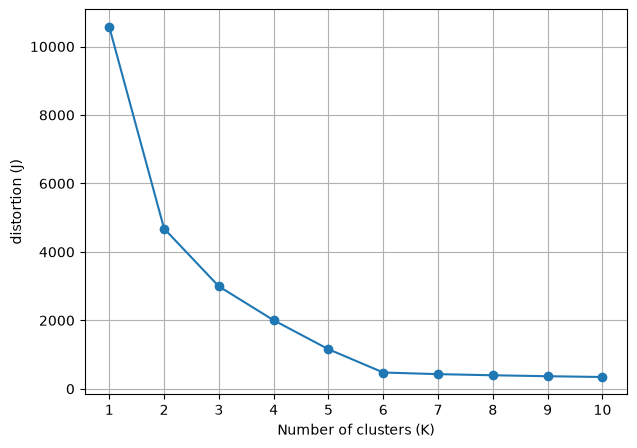

In [24]:
plt.figure(figsize=(7, 5))
plt.plot(list(K_values), best_distortions, marker="o")
plt.xticks(list(K_values))
plt.xlabel("Number of clusters (K)")
plt.ylabel("distortion (J)")

plt.grid(True)
plt.show()